In [4]:
# load data
import pandas as pd

df = pd.read_csv('air_quality_dataset.csv')
df

,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
0,39.967142,57.926035,116.192213,55.230299,4.531693,75.317261,2.789606,427.674347,1.706105,31.085120
1,101.935672,150.774299,76.826826,79.051618,18.744780,145.083987,1.966569,529.739619,2.492663,33.711103
2,70.996192,138.948796,158.731020,60.466604,14.892239,145.147338,2.626446,499.889443,2.431165,33.778698
3,28.464728,63.643900,25.385343,15.333286,7.647429,130.022319,1.779360,388.283712,1.818563,31.565877
4,78.265276,113.977926,105.644340,59.202337,17.696806,181.713667,3.240533,464.739197,2.597225,32.229835
...,...,...,...,...,...,...,...,...,...,...
495,51.380025,57.573550,31.124630,19.276010,11.167098,104.071502,1.844483,397.418878,1.923525,34.323410
496,46.816837,75.372133,22.174014,18.535162,12.169426,74.802208,1.364096,392.316075,2.157281,26.321361
497,33.909351,88.097250,27.630317,15.653370,7.997326,128.105470,2.319453,378.653347,1.809489,28.964494
498,43.721651,40.847991,27.253977,19.365916,7.218154,106.053329,1.599748,389.878566,1.858964,29.976442


In [6]:
# EDA
print(f'Cek 5 data teratas \n {df.head()} \n')

print(f'Cek tipe data \n {df.dtypes} \n')

print(f'Cek missing values \n {df.isnull().sum()}')

Cek 5 data teratas 
         PM2.5        PM10         NOx        NO2        SO2        VOCs  \
0   39.967142   57.926035  116.192213  55.230299   4.531693   75.317261   
1  101.935672  150.774299   76.826826  79.051618  18.744780  145.083987   
2   70.996192  138.948796  158.731020  60.466604  14.892239  145.147338   
3   28.464728   63.643900   25.385343  15.333286   7.647429  130.022319   
4   78.265276  113.977926  105.644340  59.202337  17.696806  181.713667   

         CO         CO2       CH4  Temperature  
0  2.789606  427.674347  1.706105    31.085120  
1  1.966569  529.739619  2.492663    33.711103  
2  2.626446  499.889443  2.431165    33.778698  
3  1.779360  388.283712  1.818563    31.565877  
4  3.240533  464.739197  2.597225    32.229835   

Cek tipe data 
 PM2.5          float64
PM10           float64
NOx            float64
NO2            float64
SO2            float64
VOCs           float64
CO             float64
CO2            float64
CH4            float64
Temperatu

In [25]:
# Cek outlier
numerical_columns = df.select_dtypes(include='number').columns

outlier_summary = []

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]

    outlier_summary.append({
        'kolom': column,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'batas_bawah': lower_bound,
        'batas_atas': upper_bound,
        'jumlah_outlier': len(outliers),
        'persen_outlier': round(len(outliers) / len(df) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)
outlier_df

,kolom,Q1,Q3,IQR,batas_bawah,batas_atas,jumlah_outlier,persen_outlier
0,PM2.5,36.372940,73.820566,37.447627,-19.798501,129.992007,0,0.0
1,PM10,61.118607,110.270086,49.151479,-12.608611,183.997305,0,0.0
2,NOx,35.457263,134.709240,99.251977,-113.420703,283.587206,0,0.0
3,NO2,17.448632,63.817763,46.369131,-52.105064,133.371459,0,0.0
4,SO2,5.976492,17.116673,11.140181,-10.733779,33.826944,0,0.0
5,VOCs,81.516729,140.588100,59.071371,-7.090328,229.195157,1,0.2
6,CO,1.536915,2.726020,1.189105,-0.246743,4.509678,5,1.0
7,CO2,397.399610,490.968315,93.568705,257.046553,631.321371,0,0.0
8,CH4,1.837395,2.386267,0.548872,1.014088,3.209574,3,0.6
9,Temperature,28.481974,32.614954,4.132980,22.282505,38.814424,4,0.8


In [12]:
# separation x and y
x = df.drop(columns = ['CO'])
y = df['CO']

In [13]:
# split data
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42
)

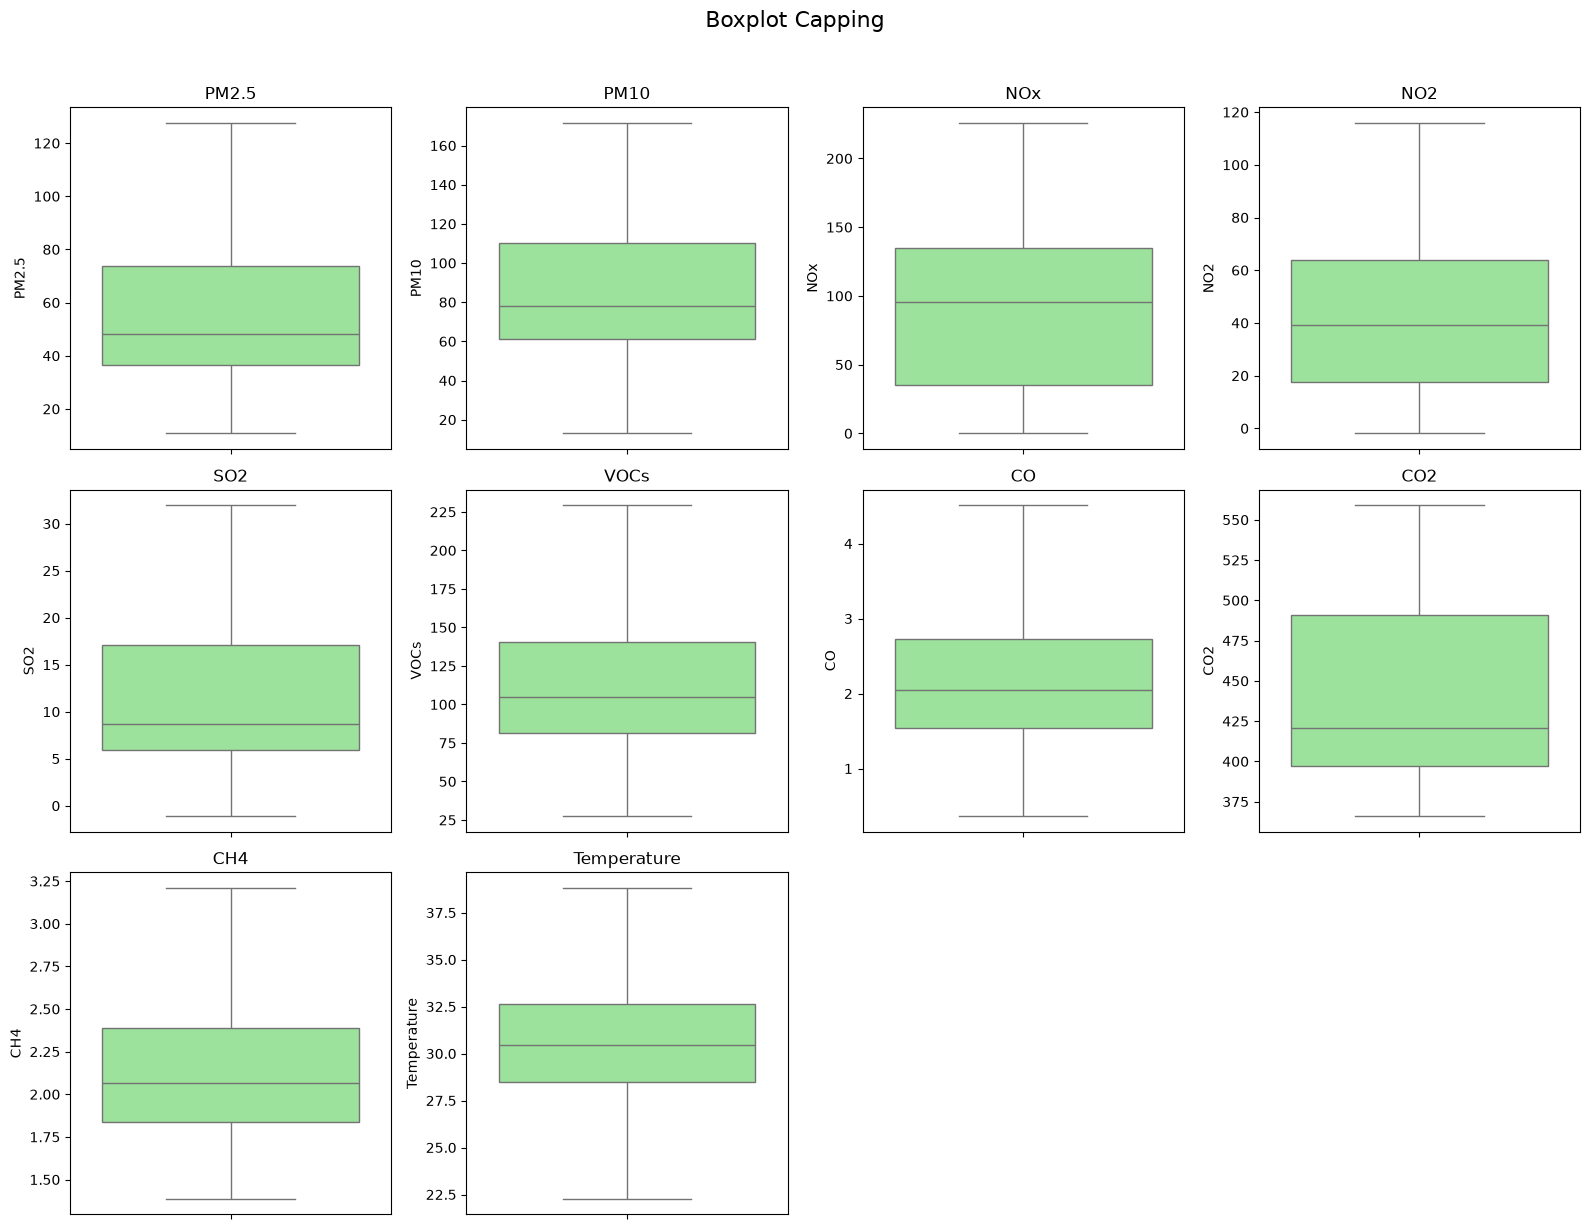

In [21]:
#handle outlier
import math
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(4 * n_cols, 4 * n_rows))
for i, column in enumerate(numerical_columns):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.boxplot(y=df_capped[column], color='lightgreen')
    plt.title(column)
plt.suptitle('Boxplot Capping', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

In [23]:
# encoding
df_encoded = pd.get_dummies(df, columns=['CO'], dtype=int)

df_encoded.head()

,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO2,CH4,Temperature,CO_0.366992172,...,CO_4.081168203,CO_4.136719495,CO_4.241948753,CO_4.391833796,CO_4.412654168,CO_4.523936853,CO_4.556831345,CO_4.607510154,CO_4.620260997,CO_4.798934925
0,39.967142,57.926035,116.192213,55.230299,4.531693,75.317261,427.674347,1.706105,31.085120,0,...,0,0,0,0,0,0,0,0,0,0
1,101.935672,150.774299,76.826826,79.051618,18.744780,145.083987,529.739619,2.492663,33.711103,0,...,0,0,0,0,0,0,0,0,0,0
2,70.996192,138.948796,158.731020,60.466604,14.892239,145.147338,499.889443,2.431165,33.778698,0,...,0,0,0,0,0,0,0,0,0,0
3,28.464728,63.643900,25.385343,15.333286,7.647429,130.022319,388.283712,1.818563,31.565877,0,...,0,0,0,0,0,0,0,0,0,0
4,78.265276,113.977926,105.644340,59.202337,17.696806,181.713667,464.739197,2.597225,32.229835,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
# training model linear regression
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](9,)","[-0. , 0. , 0. ,..., 0.01,-0.09,-0.01]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](9,)","['PM2.5','PM10','NOx',...,'CO2','CH4','Temperature']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.9529
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(9)


In [30]:
# applying model
y_lr_train_pred = lr.predict(x_train)
y_lr_test_pred = lr.predict(x_test)

In [32]:
#evaluate model
from sklearn.metrics import mean_squared_error, r2_score

lr_train_mse = mean_squared_error(y_train, y_lr_train_pred)
lr_train_r2 = r2_score(y_train, y_lr_train_pred)

lr_test_mse = mean_squared_error(y_test, y_lr_test_pred)
lr_test_r2 = r2_score(y_test, y_lr_test_pred)

In [ ]:
#training model random forest
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(max_depth=2, random_state=100)
rf.fit(x_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",100
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of 

In [38]:
# applying model
y_rf_train_pred = rf.predict(x_train)
y_rf_test_pred = rf.predict(x_test)

In [39]:
# evaluate model
from sklearn.metrics import mean_squared_error, r2_score

lr_train_mse = mean_squared_error(y_train, y_lr_train_pred)
lr_train_r2 = r2_score(y_train, y_lr_train_pred)

lr_test_mse = mean_squared_error(y_test, y_lr_test_pred)
lr_test_r2 = r2_score(y_test, y_lr_test_pred)

[]

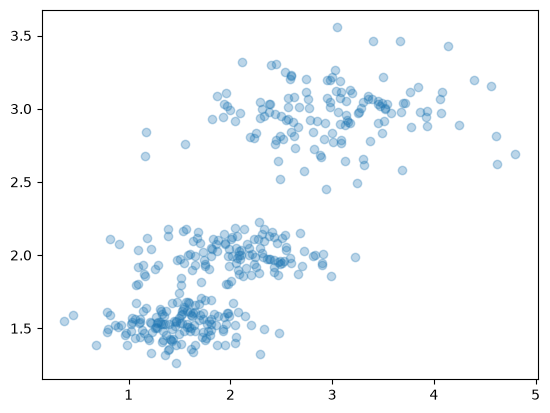

In [41]:
# visualisasi
import matplotlib.pyplot as plt

plt.scatter(x=y_train, y=y_lr_train_pred, alpha=0.3)
plt.plot()